# 05c — Vacância no tempo: com que frequência uma delegação termina?

**Para que serve este notebook (extra, fora do plano original).** O seguro do Prov. 227 paga quando a **delegação termina** (morte, aposentadoria, renúncia ou perda) e o titular deixa um passivo trabalhista sem pagar. Para estimar o sinistro, a D-025 propõe: sinistro = P(fim da delegação no ano) × P(não paga | déficit) × parte paga − recuperação. A **P(fim da delegação no ano)** é uma lacuna: ninguém publica essa taxa. Em 2026-10-18 (nota da D-025), o projeto concluiu que o cadastro do CNJ "não basta para uma taxa" e que ela seria uma **suposição com faixa**.

Este notebook volta ao cadastro para medir, com cuidado, **o que as datas permitem dizer**: quais datas são confiáveis, quantas serventias vagaram por ano, se a vacância é diferente por classe e que faixa os dados sustentam. **Não muda** nenhum dos 10 números nem nenhuma premissa: o resultado é um insumo para a decisão do autor sobre a D-025 e para a tabela de lacunas do notebook 09.

**Termos usados** (explicados onde aparecem): data da decisão, data de ingresso, decisão em lote, estoque de providas, taxa de vacância, viés de sobrevivência, taxa anualizada.

**Dados:** cadastro do Justiça Aberta (CNJ) no bronze, coletado em 17/10/2026, das 27 UFs (o pipeline usa só MG); arrecadação de 2024 do banco (carga de 19/10/2026). Do cadastro, a função `dados.cadastro_cnj` lê **só** o CNS, a UF, o status, a situação, a data da decisão, a data de ingresso do responsável e o tipo dele (titular, interino, interventor): **nome, substitutos e contatos não são lidos**, e as datas só aparecem somadas, nunca por serventia. Parâmetros em `config/analise.yaml` (`vacancia`).

In [1]:
import sys
from pathlib import Path

raiz = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(raiz))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src.analise import classificacao as cl, config, dados, enquadramento, graficos as g, vacancia as va
from src.notebooks import conectar, ler

g.estilo()
cfg = config()["vacancia"]
con = conectar()
coleta = pd.Timestamp(ler("SELECT data_referencia FROM silver.fonte_metadados WHERE fonte = 'cnj_serventias'", con=con).iloc[0, 0])
cad = dados.cadastro_cnj()
mg = cad[cad.uf == "MG"].reset_index(drop=True)
ativas = mg[mg.status == "Ativo"]
print(f"Cadastro coletado em {coleta:%d/%m/%Y}: {g.num(len(cad))} serventias em {cad.uf.nunique()} UFs; MG: {g.num(len(mg))} "
      f"({g.num(len(ativas))} ativas, o mesmo número do painel).")
print("Ativas de MG por situação:", ativas.situacao_juridica.value_counts().to_dict())

Cadastro coletado em 17/10/2026: 16.269 serventias em 27 UFs; MG: 3.213 (2.525 ativas, o mesmo número do painel).
Ativas de MG por situação: {'PROVIDO': 1654, 'VAGO': 830, 'CONVERSÃO EM DILIGÊNCIA': 28, 'SOB INTERVENÇÃO': 13}


## 1. As datas do cadastro e o quanto confiar nelas

**A pergunta.** As datas do cadastro marcam quando cada serventia mudou de situação?

**O método.** O cadastro traz duas datas por serventia, ambas só da **situação atual** (não há histórico):
- **data da decisão:** quando a situação atual (provida, vaga...) foi decidida;
- **data de ingresso:** quando o responsável atual (titular ou interino) entrou.

Procuramos datas suspeitas de duas formas: dias com muitas decisões na mesma UF (**decisão em lote**: 10 ou mais no mesmo dia, `fonte: suposição`) e anos com uma concentração fora do comum.

In [2]:
lote = va.em_lote(mg)
dias = ativas[lote[ativas.index]]
tab_lote = pd.crosstab(dias.data_decisao.dt.date.rename("dia"), dias.situacao_juridica).reset_index()
display(tab_lote)
ing24 = (ativas.data_ingresso.dt.year == cfg["ano_recadastro"]).mean()
print(f"Decisões em 2010 (dois dias): {g.num((ativas.data_decisao.dt.year < cfg['inicio_confiavel']).sum())} de {g.num(len(ativas))}. "
      f"Ingresso do responsável em {cfg['ano_recadastro']}: {g.pct(ing24)} das ativas de MG.")
por_uf = cad[cad.status == "Ativo"].groupby("uf").data_ingresso.apply(lambda s: (s.dt.year == cfg["ano_recadastro"]).mean())
print(f"Ingresso em {cfg['ano_recadastro']} nas outras UFs: de {g.pct(por_uf.min(), 0)} a {g.pct(por_uf.max(), 0)} (mediana {g.pct(por_uf.median(), 0)}).")

situacao_juridica,dia,CONVERSÃO EM DILIGÊNCIA,PROVIDO,VAGO
0,2010-07-12,0,739,88
1,2010-08-27,0,156,0
2,2011-02-03,0,11,1
3,2011-11-14,0,33,1
4,2012-02-23,0,22,0
5,2012-05-11,0,64,0
6,2013-04-01,0,110,0
7,2014-06-03,0,106,0
8,2016-06-06,0,15,0
9,2021-06-01,0,19,0


Decisões em 2010 (dois dias): 1.008 de 2.525. Ingresso do responsável em 2024: 64,5% das ativas de MG.
Ingresso em 2024 nas outras UFs: de 0% a 78% (mediana 54%).


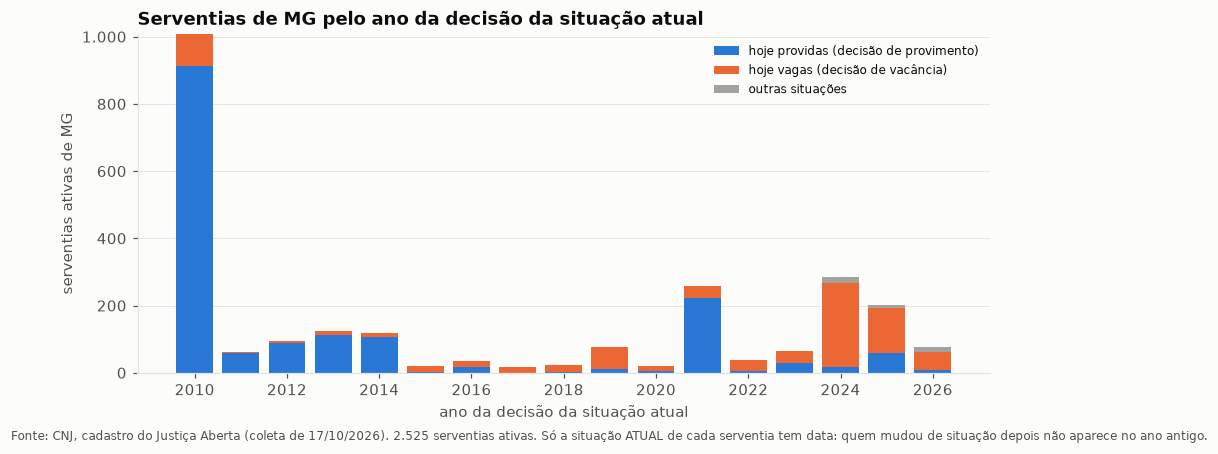

In [3]:
dec = va.decisoes_por_ano(ativas)
fig, ax = plt.subplots(figsize=(10, 4))
anos = dec.index.astype(int)
ax.bar(anos, dec.get("PROVIDO", 0), color=g.AZUL["medio"], label="hoje providas (decisão de provimento)")
ax.bar(anos, dec.get("VAGO", 0), bottom=dec.get("PROVIDO", 0), color=g.CORES[1], label="hoje vagas (decisão de vacância)")
outras = dec.drop(columns=[c for c in ["PROVIDO", "VAGO"] if c in dec]).sum(axis=1)
ax.bar(anos, outras, bottom=dec.get("PROVIDO", 0) + dec.get("VAGO", 0), color=g.CINZA, label="outras situações")
g.eixo_num(ax)
ax.set_xlabel("ano da decisão da situação atual")
ax.set_ylabel("serventias ativas de MG")
ax.set_xticks(range(anos.min(), anos.max() + 1, 2))
ax.grid(axis="x", visible=False)
ax.legend(fontsize=8)
ax.set_title("Serventias de MG pelo ano da decisão da situação atual")
g.nota(fig, f"Fonte: CNJ, cadastro do Justiça Aberta (coleta de {coleta:%d/%m/%Y}). {g.num(len(ativas))} serventias ativas. "
            "Só a situação ATUAL de cada serventia tem data: quem mudou de situação depois não aparece no ano antigo.")
g.salvar(fig, "05c_decisoes_por_ano")
plt.show()

**Como ler.** Cada barra conta as serventias ativas pelo ano em que a situação **atual** delas foi decidida: azul = hoje providas; laranja = hoje vagas.

**O que encontramos.**
- **2010:** 1.008 serventias (40% das ativas) têm a decisão em 2010, e 983 delas em só dois dias, 12/07/2010 e 27/08/2010. É muito mais provável que seja a data de carga do sistema do que 983 decisões reais em dois dias; **tratamos as decisões de 2010 como "antes de 2011, data desconhecida"** (`config/analise.yaml`, `inicio_confiavel`).
- **Lotes de provimento:** os outros lotes são quase todos de **provimento** (2011 a 2014 e junho de 2021, com 193 provimentos em 5 dias, e setembro de 2025): têm cara de outorga de concurso, quando muitos aprovados assumem de uma vez. Não são erro; são as ondas de concurso.
- **Ingresso do responsável:** **65%** das ativas de MG têm o ingresso em 2024, e o mesmo acontece em quase todas as UFs (mediana de 54%; só Alagoas não tem nenhum). Isso confirma a nota da D-025: a data de ingresso foi sobrescrita num **recadastramento em 2024** e não serve para medir tempo na delegação.
- As vacâncias aparecem a partir de 2015 e **saltam em 2024 e 2025**.

**Limitações.** O motivo das datas de 2010 e dos lotes é uma hipótese (não há documento do CNJ no projeto que explique). A data da decisão de 2024 também pode ter sido afetada pelo recadastramento (seção 3).

## 2. A taxa de vacância por ano

**A pergunta.** De cada 100 serventias providas no início de um ano, quantas vagaram naquele ano?

**O método.**
- **Vacâncias do ano** = serventias **hoje vagas** com a decisão de vacância naquele ano.
- **Providas no início do ano** (o **estoque**), reconstruído a partir do cadastro de hoje: as providas de hoje, **menos** as que foram providas naquele ano ou depois (ainda estavam vagas), **mais** as vagas cuja vacância foi decidida naquele ano ou depois (ainda estavam providas).
- **Taxa** = vacâncias ÷ estoque. Exemplo: 2.000 providas no início de 2025 e 150 vacâncias no ano dão 150 ÷ 2.000 = 7,5%.
- Mostramos a taxa com e sem as vacâncias decididas em lote (as do lote saem só do numerador).

**O viés de sobrevivência.** Só vemos as vacâncias de quem **continua vaga** hoje. Uma serventia que vagou em 2015 e foi provida por concurso em 2021 aparece hoje como "provida em 2021": a vacância de 2015 sumiu. Por isso, quanto mais antigo o ano, mais a taxa é **subestimada**. As taxas antigas são um **piso**, não a taxa real.

In [4]:
taxas = va.taxas_por_ano(mg, range(cfg["inicio_confiavel"], coleta.year + 1))
taxas_lote = va.taxas_por_ano(mg, range(cfg["inicio_confiavel"], coleta.year + 1), sem_lote=False)
taxas["taxa_com_lotes"] = taxas_lote.taxa.values
fracao_ano = coleta.dayofyear / pd.Timestamp(coleta.year, 12, 31).dayofyear
taxas["taxa_anualizada"] = np.where(taxas.ano == coleta.year, taxas_lote.taxa / fracao_ano, taxas_lote.taxa)
display(g.tabela(taxas, {"providas_no_inicio": "int", "vacancias": "int", "taxa": "pct", "taxa_com_lotes": "pct",
                         "taxa_anualizada": "pct"})
        .rename(columns={"vacancias": "vacâncias (sem lote)", "taxa": "taxa sem lote", "taxa_com_lotes": "taxa (todas)",
                         "taxa_anualizada": "taxa (todas, anualizada)"}))
print(f"{coleta.year} vai só até a coleta ({g.pct(fracao_ano, 0)} do ano): a taxa anualizada divide pela fração do ano.")
r = taxas.set_index("ano")
print(f"Média de 2021 a 2023 (todas): {g.pct(r.loc[2021:2023, 'taxa_com_lotes'].mean())}; 2025: {g.pct(r.loc[2025, 'taxa_com_lotes'])}; "
      f"{coleta.year} anualizada: {g.pct(r.loc[coleta.year, 'taxa_anualizada'])}.")

,ano,providas_no_inicio,vacâncias (sem lote),taxa sem lote,taxa (todas),"taxa (todas, anualizada)"
0,2011,1.646,3,"0,2%","0,3%","0,3%"
1,2012,1.699,5,"0,3%","0,3%","0,3%"
2,2013,1.783,12,"0,7%","0,7%","0,7%"
3,2014,1.882,11,"0,6%","0,6%","0,6%"
4,2015,1.979,20,"1,0%","1,0%","1,0%"
5,2016,1.960,18,"0,9%","0,9%","0,9%"
6,2017,1.958,18,"0,9%","0,9%","0,9%"
7,2018,1.940,22,"1,1%","1,1%","1,1%"
8,2019,1.919,66,"3,4%","3,4%","3,4%"
9,2020,1.863,13,"0,7%","0,7%","0,7%"


2026 vai só até a coleta (79% do ano): a taxa anualizada divide pela fração do ano.
Média de 2021 a 2023 (todas): 1,8%; 2025: 7,5%; 2026 anualizada: 4,0%.


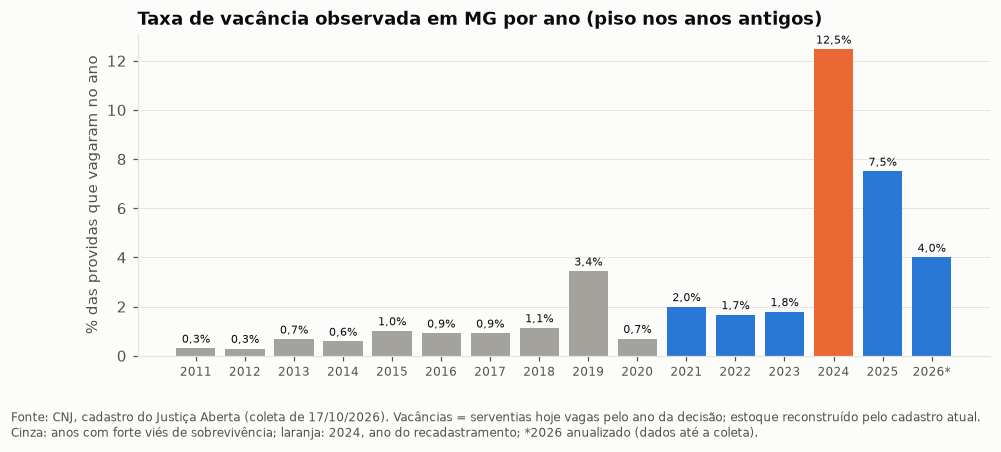

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.8))
cor = [g.CINZA if a < 2021 else (g.CORES[1] if a == cfg["ano_recadastro"] else g.AZUL["medio"]) for a in taxas.ano]
b = ax.bar(taxas.ano, 100 * taxas.taxa_anualizada, color=cor)
ax.bar_label(b, [g.pct(v, 1) for v in taxas.taxa_anualizada], fontsize=7, padding=2)
ax.set_xticks(taxas.ano, [str(a) if a != coleta.year else f"{a}*" for a in taxas.ano], fontsize=8)
ax.set_ylabel("% das providas que vagaram no ano")
ax.grid(axis="x", visible=False)
ax.set_title("Taxa de vacância observada em MG por ano (piso nos anos antigos)")
g.nota(fig, f"Fonte: CNJ, cadastro do Justiça Aberta (coleta de {coleta:%d/%m/%Y}). Vacâncias = serventias hoje vagas pelo ano "
            f"da decisão; estoque reconstruído pelo cadastro atual.\nCinza: anos com forte viés de sobrevivência; laranja: "
            f"{cfg['ano_recadastro']}, ano do recadastramento; *{coleta.year} anualizado (dados até a coleta).")
g.salvar(fig, "05c_taxa_vacancia_mg_por_ano")
plt.show()

**Como ler.** Cada barra é a % das providas no início do ano que vagaram naquele ano, com todas as vacâncias (inclusive as em lote). Cinza: anos com viés de sobrevivência forte; laranja: o ano do recadastramento.

**O que encontramos.**
- **Até 2020**, a taxa observada fica em cerca de 1% ou menos (a exceção é 2019, com 3,4%). É um piso muito baixo: as ondas de concurso de 2013, 2014 e 2021 proveram centenas de serventias, e as vacâncias anteriores a elas sumiram do cadastro.
- **2021 a 2023:** cerca de **2% ao ano**. Ainda é piso, mas com menos tempo para as vagas terem sido providas.
- **2024: 12,5%** e **2025: 7,5%**. **2026, anualizado: cerca de 4%**.

**O que significa.** A taxa recente fica entre **2% e 7,5%**, e os anos mais confiáveis (2025 e o começo de 2026) apontam para algo como **4% a 7,5% ao ano**. A seção 3 olha se 2024 e 2025 são reais.

**Limitações.** O estoque reconstruído ignora quem mudou de situação mais de uma vez no período e as serventias que foram extintas (as inativas não entram). A anualização de 2026 supõe que as vacâncias se distribuem igualmente pelo ano.

## 3. As vacâncias de 2024 e 2025 são reais?

**A pergunta.** O salto de 2024–25 é um aumento real de vacâncias ou efeito do recadastramento?

**O método.** Duas conferências:
1. **O ingresso do interino.** Quando uma serventia vaga, um interino assume. Se o interino entrou bem antes da "decisão de vacância", a data da decisão não marca o momento em que a serventia vagou. Se o ingresso dele é de 2024, não dá para saber (é a data do recadastramento).
2. **Outras UFs.** Se o salto aparece em todos os estados ao mesmo tempo, ele pode ser do sistema; se cada estado tem um padrão diferente, há atos locais.

,ano da decisão,vagas,interino com ingresso em 2024,interino entrou antes da decisão,interino entrou na decisão ou depois
0,2021,37,29,7,30
1,2022,34,25,6,28
2,2023,36,24,7,29
3,2024,250,226,102,148
4,2025,133,11,98,35
5,2026,54,1,10,44


Vagas de 2025 com o interino entrando antes da decisão (fora os ingressos de 2024): 87; o interino entrou em 2025 em 78 delas; distância mediana: 4 dias (P75: 10).
2025 nas UFs: mediana 11,1%; MG 7,5%; de 0% a 60% (maior: AL).


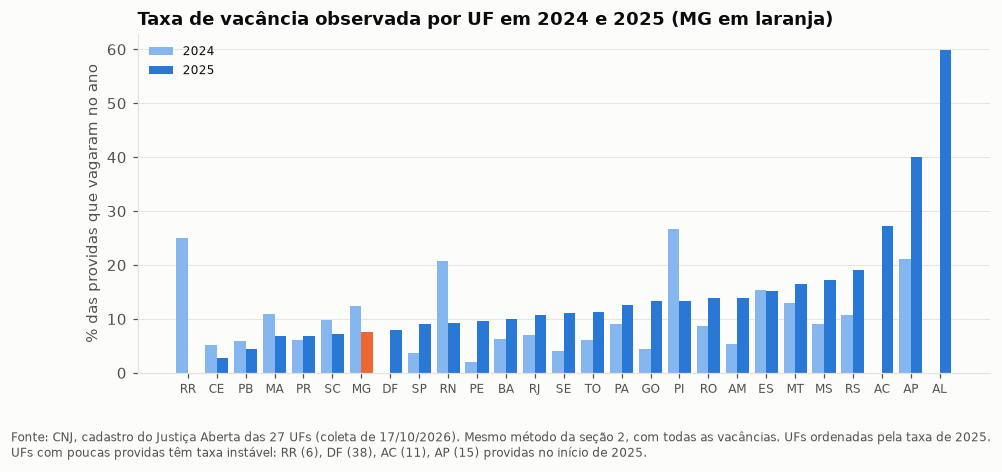

In [6]:
vagas = ativas[ativas.situacao_juridica == "VAGO"]
linhas = []
for ano in range(2021, coleta.year + 1):
    x = vagas[vagas.data_decisao.dt.year == ano]
    linhas.append({"ano da decisão": ano, "vagas": len(x),
                   "interino com ingresso em 2024": int((x.data_ingresso.dt.year == cfg["ano_recadastro"]).sum()),
                   "interino entrou antes da decisão": int((x.data_ingresso < x.data_decisao).sum()),
                   "interino entrou na decisão ou depois": int((x.data_ingresso >= x.data_decisao).sum())})
display(pd.DataFrame(linhas))
x25 = vagas[(vagas.data_decisao.dt.year == 2025) & (vagas.data_ingresso < vagas.data_decisao)
            & (vagas.data_ingresso.dt.year != cfg["ano_recadastro"])]
dias_antes = (x25.data_decisao - x25.data_ingresso).dt.days
print(f"Vagas de 2025 com o interino entrando antes da decisão (fora os ingressos de {cfg['ano_recadastro']}): {g.num(len(x25))}; "
      f"o interino entrou em 2025 em {g.num((x25.data_ingresso.dt.year == 2025).sum())} delas; distância mediana: "
      f"{g.num(dias_antes.median())} dias (P75: {g.num(dias_antes.quantile(0.75))}).")
uf25 = va.taxa_vacancia(cad, 2025, cad.uf).sort_values("taxa")
uf24 = va.taxa_vacancia(cad, cfg["ano_recadastro"], cad.uf)
uf25["taxa_2024"] = uf24.taxa
print(f"2025 nas UFs: mediana {g.pct(uf25.taxa.median())}; MG {g.pct(uf25.loc['MG', 'taxa'])}; de {g.pct(uf25.taxa.min(), 0)} a "
      f"{g.pct(uf25.taxa.max(), 0)} (maior: {uf25.taxa.idxmax()}).")

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(uf25))
ax.bar(x - 0.2, 100 * uf25.taxa_2024, width=0.4, color=g.AZUL["claro"], label=str(cfg["ano_recadastro"]))
ax.bar(x + 0.2, 100 * uf25.taxa, width=0.4, color=[g.CORES[1] if u == "MG" else g.AZUL["medio"] for u in uf25.index], label="2025")
ax.set_xticks(x, uf25.index, fontsize=8)
ax.set_ylabel("% das providas que vagaram no ano")
ax.grid(axis="x", visible=False)
ax.legend(fontsize=8)
ax.set_title("Taxa de vacância observada por UF em 2024 e 2025 (MG em laranja)")
g.nota(fig, f"Fonte: CNJ, cadastro do Justiça Aberta das 27 UFs (coleta de {coleta:%d/%m/%Y}). Mesmo método da seção 2, com todas "
            "as vacâncias. UFs ordenadas pela taxa de 2025.\nUFs com poucas providas têm taxa instável: "
            + ", ".join(f"{u} ({g.num(n)})" for u, n in uf25.providas_no_inicio[uf25.providas_no_inicio < 50].items())
            + " providas no início de 2025.")
g.salvar(fig, "05c_taxa_vacancia_por_uf")
plt.show()

**Como ler.** A tabela mostra, para as vagas de cada ano, quando o interino entrou. O gráfico compara as UFs em 2024 (azul claro) e 2025.

**O que encontramos.**
- **2024 está contaminado:** 226 das 250 vagas "decididas" em 2024 têm o interino com ingresso em 2024, a data do recadastramento. Não dá para saber se vagaram em 2024 ou se só tiveram as datas refeitas. **A taxa de 2024 (12,5%) não deve ser usada.**
- **2025 é mais limpo:** só 11 das 133 vagas têm ingresso de 2024. Fora esses 11, em 87 o interino entrou **antes** da decisão formal, 78 delas no próprio ano de 2025, com distância mediana de só **4 dias**: a data da decisão marca, de fato, o momento em que a serventia vagou.
- Entre as UFs, as taxas de 2025 vão de quase 0 a 60% (Alagoas, onde quase toda a vacância do estado está em 2025 e 2026). Esse padrão espalhado sugere **atos locais** de cada tribunal, e não uma taxa "natural" comum. MG (7,5%) fica abaixo da mediana das UFs.

**Limitações.** Parte das vacâncias de 2025 pode ser a formalização de vacâncias antigas (o tribunal declarando de uma vez situações que já existiam). Não há como separar com o cadastro.

## 4. A vacância é igual em todas as classes?

**A pergunta.** As serventias grandes (Classes 2 e 3, as obrigadas) vagam tanto quanto as pequenas?

**O método.** A taxa da seção 2, separada pela **classe da receita do ano anterior** (média dos semestres > 0, a regra da D-010, com os limites da regra v2). Para as vacâncias de 2025, a receita de 2024 foi medida **antes** de a serventia vagar, quando ainda tinha titular: aqui **não há o vazamento** do notebook 05a. Também mostramos 2024, com a ressalva da seção 3.

,ano,classe,providas_no_inicio,vacancias,taxa
0,2024,1,1.029,180,"17,5%"
1,2024,2,688,36,"5,2%"
2,2024,3,266,19,"7,1%"
4,2025,1,769,92,"12,0%"
5,2025,2,719,24,"3,3%"
6,2025,3,281,15,"5,3%"


2025, Classes 2 e 3 juntas (o tamanho das obrigadas): 39 de 1.000 = 3,9% (intervalo de 95%: 2,7% a 5,1%); Classe 1: 12,0%.
Providas sem receita em 2024 que entram no estoque de 2025 (fora da tabela): 4.


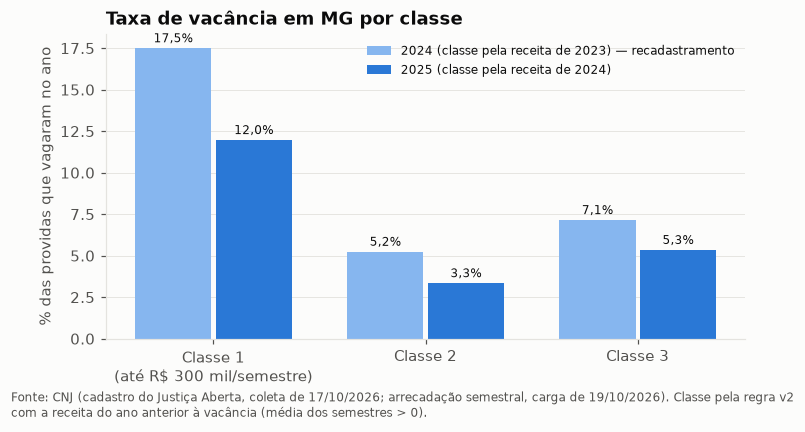

In [7]:
media, _ = cl.receita_anual(dados.serie_arrecadacao(con))
por_classe = []
for ano in [cfg["ano_recadastro"], 2025]:
    classe = enquadramento.classe_pela_receita(mg.cns.map(media.get(ano - 1))).fillna("sem receita")
    t = va.taxa_vacancia(mg, ano, classe)
    t["ano"] = ano
    por_classe.append(t.reset_index(names="classe"))
por_classe = pd.concat(por_classe, ignore_index=True)
por_classe = por_classe[por_classe.classe != "sem receita"]
display(g.tabela(por_classe[["ano", "classe", "providas_no_inicio", "vacancias", "taxa"]],
                 {"providas_no_inicio": "int", "vacancias": "int", "taxa": "pct"}))
c25 = por_classe[por_classe.ano == 2025].set_index("classe")
obrig25 = c25.loc[["2", "3"], "vacancias"].sum() / c25.loc[["2", "3"], "providas_no_inicio"].sum()
n23, k23 = c25.loc[["2", "3"], "providas_no_inicio"].sum(), c25.loc[["2", "3"], "vacancias"].sum()
ep = np.sqrt(obrig25 * (1 - obrig25) / n23)   # erro padrão de uma proporção (aproximação normal)
print(f"2025, Classes 2 e 3 juntas (o tamanho das obrigadas): {g.num(k23)} de {g.num(n23)} = {g.pct(obrig25)} "
      f"(intervalo de 95%: {g.pct(obrig25 - 1.96 * ep)} a {g.pct(obrig25 + 1.96 * ep)}); Classe 1: {g.pct(c25.loc['1', 'taxa'])}.")
sem_rec = va.taxa_vacancia(mg, 2025, enquadramento.classe_pela_receita(mg.cns.map(media.get(2024))).fillna("sem receita"))
print(f"Providas sem receita em 2024 que entram no estoque de 2025 (fora da tabela): {g.num(sem_rec.loc['sem receita', 'providas_no_inicio']) if 'sem receita' in sem_rec.index else 0}.")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
xc = np.arange(3)
for j, (ano, corb) in enumerate([(cfg["ano_recadastro"], g.AZUL["claro"]), (2025, g.AZUL["medio"])]):
    t = por_classe[por_classe.ano == ano].set_index("classe").reindex(["1", "2", "3"])
    bb = ax.bar(xc + (j - 0.5) * 0.38, 100 * t.taxa, width=0.36, color=corb,
                label=f"{ano} (classe pela receita de {ano - 1})" + (" — recadastramento" if ano == cfg["ano_recadastro"] else ""))
    ax.bar_label(bb, [g.pct(v) for v in t.taxa], fontsize=8, padding=2)
ax.set_xticks(xc, [f"Classe 1\n(até {g.reais(enquadramento.limites_classe()[0], 0)}/semestre)", "Classe 2", "Classe 3"])
ax.set_ylabel("% das providas que vagaram no ano")
ax.grid(axis="x", visible=False)
ax.legend(fontsize=8)
ax.set_title("Taxa de vacância em MG por classe")
g.nota(fig, f"Fonte: CNJ (cadastro do Justiça Aberta, coleta de {coleta:%d/%m/%Y}; arrecadação semestral, carga de 19/10/2026). "
            "Classe pela regra v2\ncom a receita do ano anterior à vacância (média dos semestres > 0).")
g.salvar(fig, "05c_taxa_vacancia_por_classe")
plt.show()

**Como ler.** Para cada classe (pela receita do ano anterior), a % das providas que vagaram no ano.

**O que encontramos.**
- Em 2025, as serventias da **Classe 1** vagaram **12%**, contra **3,3% na Classe 2** e **5,3% na Classe 3**. Somando as Classes 2 e 3 (o tamanho das obrigadas), cerca de **4%**.
- Em 2024, com a ressalva do recadastramento, o padrão é o mesmo: a Classe 1 vaga muito mais (17,5%), as Classes 2 e 3 entre 5% e 7%.

**O que significa para o Prov. 227.** A vacância se concentra nos cartórios **pequenos**, que são dispensados do seguro. Entre os do tamanho das obrigadas, a taxa observada é bem menor: **cerca de 4% a 5% ao ano**. É o mesmo padrão do notebook 05a (vagas são pequenas), agora sem o vazamento, porque a receita foi medida antes de vagar.

**Limitações.** São só dois anos, e 2024 está contaminado. Com 39 vacâncias em 1.000 providas nas Classes 2 e 3 em 2025, a taxa tem incerteza grande: o intervalo de 95% (impresso acima, aproximação normal) vai de cerca de 2,7% a 5,1%, sem contar os problemas de data. Quatro providas sem receita em 2024 ficam fora da tabela.

## 5. Que faixa os dados sustentam para a P(fim da delegação no ano)?

**A pergunta.** Que valor usar para a chance de uma delegação terminar no ano, no cálculo do sinistro (D-025)?

**O método.** Juntamos as pistas das seções anteriores, da mais baixa à mais alta, para as serventias do tamanho das obrigadas.

In [8]:
pistas = pd.DataFrame([
    {"pista": "2021–2023, todas as classes (piso: viés de sobrevivência)", "taxa": r.loc[2021:2023, "taxa_com_lotes"].mean()},
    {"pista": f"{coleta.year}, todas as classes, anualizada (ano incompleto)", "taxa": r.loc[coleta.year, "taxa_anualizada"]},
    {"pista": "2025, Classes 2 e 3 (receita de 2024, sem vazamento)", "taxa": obrig25},
    {"pista": "2025, todas as classes", "taxa": r.loc[2025, "taxa_com_lotes"]},
    {"pista": f"{cfg['ano_recadastro']}, todas as classes (contaminada pelo recadastramento; não usar)", "taxa": r.loc[cfg["ano_recadastro"], "taxa_com_lotes"]},
])
display(g.tabela(pistas, {"taxa": "pct"}))
n_obrig = ler("SELECT n_universo FROM gold.fato_mercado_uf WHERE uf = 'MG' AND nivel = 'base' AND regra_classe = 'v2' "
              "AND cenario_stf = 'mantem'", con=con).iloc[0, 0]
for t in [r.loc[2021:2023, "taxa_com_lotes"].mean(), obrig25, r.loc[2025, "taxa_com_lotes"]]:
    print(f"Com {g.pct(t)} ao ano, das ≈ {g.num(n_obrig)} obrigadas de hoje, ≈ {g.num(t * n_obrig)} delegações terminariam por ano.")

,pista,taxa
0,"2021–2023, todas as classes (piso: viés de sob...","1,8%"
1,"2026, todas as classes, anualizada (ano incomp...","4,0%"
2,"2025, Classes 2 e 3 (receita de 2024, sem vaza...","3,9%"
3,"2025, todas as classes","7,5%"
4,"2024, todas as classes (contaminada pelo recad...","12,5%"


Com 1,8% ao ano, das ≈ 1.121 obrigadas de hoje, ≈ 20 delegações terminariam por ano.
Com 3,9% ao ano, das ≈ 1.121 obrigadas de hoje, ≈ 44 delegações terminariam por ano.
Com 7,5% ao ano, das ≈ 1.121 obrigadas de hoje, ≈ 84 delegações terminariam por ano.


**O que encontramos.**
- O **piso** dos dados é de cerca de **2% ao ano** (2021–23, subestimado pelo viés de sobrevivência).
- A melhor pista para as obrigadas é a de **2025 nas Classes 2 e 3: 3,9%**, com um intervalo estatístico de 2,7% a 5,1%. A de 2026 anualizada (4,0%, todas as classes) é parecida.
- O **teto razoável** é **7,5%** (2025, todas as classes, puxado pela Classe 1).
- Com ≈ 1.121 obrigadas, isso dá algo entre **≈ 20 e ≈ 84 fins de delegação por ano**, com o valor central perto de **44**.

**O que significa para o seguro.** O sinistro esperado é proporcional a essa taxa: dobrar a taxa dobra o sinistro. A faixa de **2% a 7,5%** (central perto de 4%) é uma base de dados, ainda que fraca, para a suposição da D-025, que hoje não tem número. **Proposta ao autor** (nada foi mudado): usar 4% como base, 2% como mínimo e 7,5% como máximo da P(fim da delegação no ano), com a fonte "notebook 05c", e refazer a conta quando houver uma segunda coleta do cadastro (com duas fotos, dá para ver quem mudou de situação entre elas, sem o viés de sobrevivência).

**Limitações.**
- A vacância **não é igual** ao sinistro: uma delegação que termina sem passivo descoberto não gera sinistro, e a vacância pode ser por motivos (como a renúncia para assumir outra serventia) em que o titular continua pagando.
- O cadastro só tem a situação atual; a taxa vem de uma reconstrução, com viés de sobrevivência nos anos antigos e com o recadastramento de 2024 nos recentes.
- As taxas variam muito entre UFs (seção 3): a de MG não vale automaticamente para outro estado.

## 6. Conclusões

1. **As datas do cadastro só servem em parte.** A data de ingresso do responsável foi sobrescrita no recadastramento de 2024 (65% das ativas de MG); as decisões de 2010 parecem data de carga; os lotes de 2011–2014, 2021 e 2025 são ondas de provimento por concurso.
2. **A taxa de vacância observada em MG** fica perto de 2% ao ano em 2021–23 (piso), 7,5% em 2025 e cerca de 4% em 2026 (anualizada). A de 2024 (12,5%) está contaminada pelo recadastramento.
3. **Vagam mais as serventias pequenas:** em 2025, 12% na Classe 1 contra 3,9% nas Classes 2 e 3, com a receita medida antes de vagar.
4. **Faixa proposta para a P(fim da delegação no ano), para o autor decidir (D-025):** 2% a 7,5%, com central perto de 4%: ≈ 44 fins de delegação por ano entre as ≈ 1.121 obrigadas.
5. **Uma segunda coleta do cadastro** (gratuita: a mesma API do CNJ) resolveria boa parte do problema, porque permitiria ver as mudanças de situação entre duas datas. É a melhor "fonte nova" para esta lacuna (notebook 09).